# Индивидуальный цифровой проект. Этап 3
## Очистка, анализ данных и масштабирование признаков

**Датасет:** [Airlines Delay](https://www.kaggle.com/datasets/jimschacko/airlines-dataset-to-predict-a-delay) (Kaggle), файл `Airlines.csv`.
**Задача:** бинарная классификация - предсказать, задержится ли рейс (`Delay` = 1) или нет (`Delay` = 0).

Признаки:
- `Airline` - код авиакомпании
- `Flight` - номер рейса
- `AirportFrom`, `AirportTo` - аэропорт вылета и прилёта
- `DayOfWeek` - день недели (1-7)
- `Time` - время вылета в минутах от полуночи
- `Length` - длительность полёта в минутах

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, MaxAbsScaler
from sklearn.model_selection import train_test_split

%matplotlib inline
pd.set_option("display.float_format", "{:.4g}".format)

## 1 Загрузка данных


In [45]:
df = pd.read_csv("Airlines.csv")
print(df.shape)
df.head()

(539383, 9)


,id,Airline,Flight,AirportFrom,AirportTo,DayOfWeek,Time,Length,Delay
0,1,CO,269,SFO,IAH,3,15,205,1
1,2,US,1558,PHX,CLT,3,15,222,1
2,3,AA,2400,LAX,DFW,3,20,165,1
3,4,AA,2466,SFO,DFW,3,20,195,1
4,5,AS,108,ANC,SEA,3,30,202,0


In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 539383 entries, 0 to 539382
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   id           539383 non-null  int64 
 1   Airline      539383 non-null  object
 2   Flight       539383 non-null  int64 
 3   AirportFrom  539383 non-null  object
 4   AirportTo    539383 non-null  object
 5   DayOfWeek    539383 non-null  int64 
 6   Time         539383 non-null  int64 
 7   Length       539383 non-null  int64 
 8   Delay        539383 non-null  int64 
dtypes: int64(6), object(3)
memory usage: 37.0+ MB


## 2 Очистка данных
По результатам аудита на этапе 2 в данных нет пропусков в привычном виде, но есть проблемы: рейсы с нулевой длительностью, подозрительно короткие и длинные перелёты для своего маршрута, а категориальные признаки хранятся как числа и строки.

### 2.1 Пропуски и дубликаты

In [47]:
print("пропусков всего:", df.isna().sum().sum())
print("полных дубликатов:", df.duplicated().sum())
print("дубликатов без id:", df.drop(columns="id").duplicated().sum())

пропусков всего: 0
полных дубликатов: 0
дубликатов без id: 216618


Полностью одинаковых строк нет. Строки, совпадающие без `id`, я не удаляю: один и тот же рейс может летать в разные недели, а дата в датасете не указана, поэтому это скорее разные полёты, а не ошибка.

### 2.2 Нулевая длительность

In [48]:
zero = df["Length"] == 0
print("рейсов с Length = 0:", zero.sum())
df[zero].head()

рейсов с Length = 0: 4


,id,Airline,Flight,AirportFrom,AirportTo,DayOfWeek,Time,Length,Delay
179149,179150,F9,106,DEN,MSP,6,635,0,0
182840,182841,F9,107,MSP,DEN,6,851,0,0
188953,188954,F9,103,MSP,DEN,7,375,0,0
445578,445579,B6,493,BOS,SEA,7,1060,0,1


Полёт не может длиться 0 минут, это ошибка в данных. Удалять такие строки не хочу, лучше заменить нули медианной длительностью того же маршрута (пара аэропорт вылета - аэропорт прилёта). Если маршрут встречается только с нулями, беру общую медиану.

In [49]:
df["length_was_zero"] = zero.astype(int)
df.loc[zero, "Length"] = np.nan
route_median = df.groupby(["AirportFrom", "AirportTo"])["Length"].transform("median")
df["Length"] = df["Length"].fillna(route_median).fillna(df["Length"].median())
print("осталось нулей:", (df["Length"] == 0).sum(), " пропусков:", df["Length"].isna().sum())

осталось нулей: 0  пропусков: 0


### 2.3 Подозрительная длительность
Сравниваю длительность каждого рейса с медианой его маршрута. Если рейс в 2 раза короче или в 2 раза длиннее обычного, отмечаю его как подозрительный.

In [50]:
route_median = df.groupby(["AirportFrom", "AirportTo"])["Length"].transform("median")
ratio = df["Length"] / route_median
df["length_suspect"] = ((ratio < 0.5) | (ratio > 2)).astype(int)
print("подозрительных рейсов:", df["length_suspect"].sum(), f"({df['length_suspect'].mean():.2%})")

подозрительных рейсов: 10 (0.00%)


Таких рейсов мало. Это может быть и ошибка, и реальная ситуация (например, рейс с промежуточной посадкой). Оставляю флаг `length_suspect`, модель сама решит, полезен ли он.

### 2.4 Типы

In [51]:
for col in ["Airline", "AirportFrom", "AirportTo", "Flight", "DayOfWeek"]:
    df[col] = df[col].astype("category")
df.dtypes

,0
id,int64
Airline,category
Flight,category
AirportFrom,category
AirportTo,category
DayOfWeek,category
Time,int64
Length,float64
Delay,int64
length_was_zero,int64


После очистки датасет такой же по размеру, ничего не удалено, добавлено два флага.

## 3 Часть 1 - Анализ данных
Беру случайные 30% строк. На них смотрю данные и придумываю гипотезы, а проверяю гипотезы на остальных 70%, которые до этого не трогаю. Так гипотеза не подгоняется под те же данные, на которых её проверяют.

In [52]:
explore = df.sample(frac=0.3, random_state=42)
check = df.drop(explore.index)
print("для анализа:", len(explore), " для проверки:", len(check))

для анализа: 161815  для проверки: 377568


### 3.1 Среднее и медиана

In [53]:
stats = explore[["Length", "Time"]].agg(["mean", "median"]).T
stats["разница"] = stats["mean"] - stats["median"]
stats.round(1)

,mean,median,разница
Length,132,115,17
Time,802.7,795,7.7


У `Length` среднее (около 132 минут) больше медианы (115). Значит, распределение скошено вправо: большинство рейсов короткие, но есть хвост длинных перелётов, который тянет среднее вверх. У `Time` среднее и медиана почти совпадают, вылеты распределены по дню более равномерно.

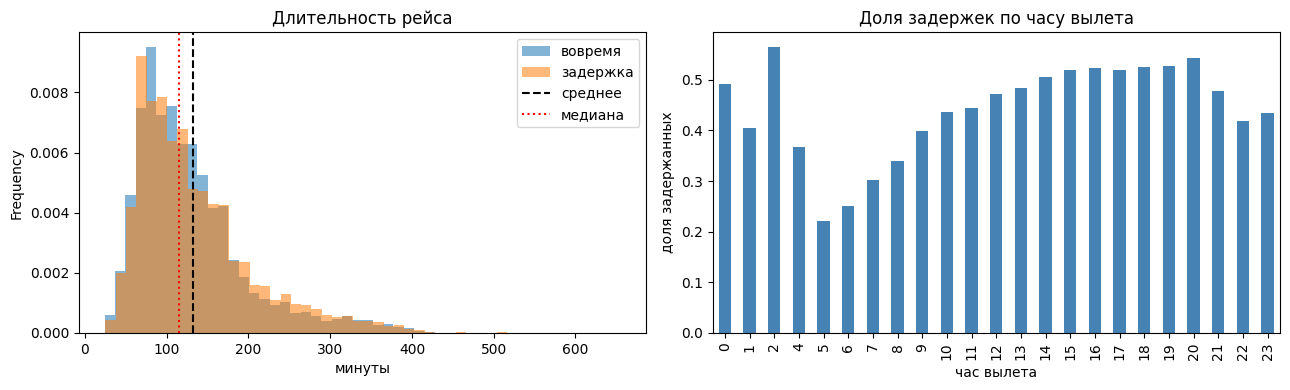

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for d, label in [(0, "вовремя"), (1, "задержка")]:
    explore.loc[explore["Delay"] == d, "Length"].plot(kind="hist", bins=50, alpha=0.55, ax=ax[0], label=label, density=True)
ax[0].axvline(explore["Length"].mean(), color="black", ls="--", label="среднее")
ax[0].axvline(explore["Length"].median(), color="red", ls=":", label="медиана")
ax[0].set_title("Длительность рейса")
ax[0].set_xlabel("минуты")
ax[0].legend()

hour = explore["Time"] // 60
explore.groupby(hour)["Delay"].mean().plot(kind="bar", ax=ax[1], color="steelblue")
ax[1].set_title("Доля задержек по часу вылета")
ax[1].set_xlabel("час вылета")
ax[1].set_ylabel("доля задержанных")
plt.tight_layout()
plt.show()

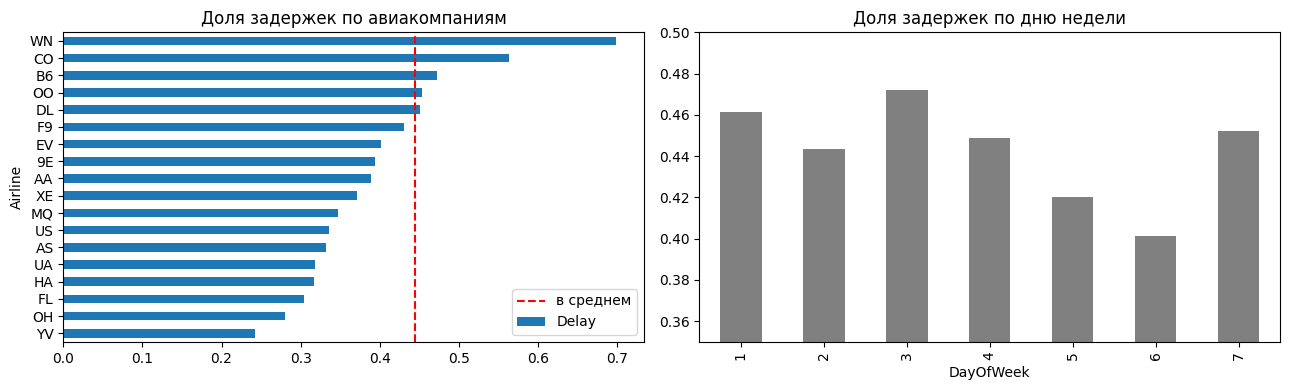

In [55]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
explore.groupby("Airline", observed=True)["Delay"].mean().sort_values().plot(kind="barh", ax=ax[0])
ax[0].axvline(explore["Delay"].mean(), color="red", ls="--", label="в среднем")
ax[0].set_title("Доля задержек по авиакомпаниям")
ax[0].legend()
explore.groupby("DayOfWeek", observed=True)["Delay"].mean().plot(kind="bar", ax=ax[1], color="gray")
ax[1].set_title("Доля задержек по дню недели")
ax[1].set_ylim(0.35, 0.5)
plt.tight_layout()
plt.show()

### 3.2 Гипотезы
Что видно на графиках:

**Гипотеза 1. Дневные и вечерние рейсы задерживаются чаще утренних.**
На графике по часам доля задержек растёт в течение дня: рано утром около трети рейсов задерживаются, а после обеда уже примерно половина. Думаю, задержки копятся: самолёт опоздал на первый рейс и дальше весь день летает с опозданием. Делю день на части и сравниваю утро (6:00-12:00) с днём и вечером (12:00-24:00).

**Гипотеза 2. Рейсы Southwest (WN) задерживаются чаще остальных.**
На графике по авиакомпаниям WN сильно выбивается: около 70% задержек при среднем около 44%. При этом WN - самая большая авиакомпания в данных (около 17% всех рейсов), так что это не случайность на маленькой выборке.

**Гипотеза 3. Самые длинные рейсы задерживаются чаще.**
На гистограмме длительности хвост справа у задержанных рейсов чуть толще. Проверяю четверть самых длинных рейсов против остальных. Возможное объяснение: длинные рейсы чаще летят через большие загруженные аэропорты.

Сначала считаю всё на выборке для анализа, потом то же самое на проверочной части. Чтобы понять, что разница не случайная, использую критерий хи-квадрат (таблица сопряжённости "группа x задержка").

In [56]:
def part_of_day(t):
    return pd.cut(t, [0, 360, 720, 1080, 1440], right=False, labels=["ночь", "утро", "день", "вечер"])


def compare(data, mask, name_a, name_b):
    # доли задержек в двух группах и p-value хи-квадрат
    table = pd.crosstab(mask, data["Delay"])
    p = chi2_contingency(table)[1]
    a = data.loc[mask, "Delay"].mean()
    b = data.loc[~mask, "Delay"].mean()
    return pd.Series({name_a: round(a, 3), name_b: round(b, 3), "разница": round(a - b, 3), "p-value": p})

### Гипотеза 1

In [57]:
pd.DataFrame({
    "анализ (30%)": explore.groupby(part_of_day(explore["Time"]), observed=True)["Delay"].mean(),
    "проверка (70%)": check.groupby(part_of_day(check["Time"]), observed=True)["Delay"].mean(),
}).round(3)

,анализ (30%),проверка (70%)
Time,,
ночь,0.276,0.281
утро,0.359,0.366
день,0.503,0.5
вечер,0.513,0.515


In [58]:
pd.DataFrame({
    "анализ (30%)": compare(explore, explore["Time"] >= 720, "после 12:00", "до 12:00"),
    "проверка (70%)": compare(check, check["Time"] >= 720, "после 12:00", "до 12:00"),
})

,анализ (30%),проверка (70%)
после 12:00,0.507,0.505
до 12:00,0.357,0.363
разница,0.15,0.142
p-value,0,0


На проверочной части картина та же: утром задерживается около 37% рейсов, днём и вечером около 50%. p-value практически ноль, так что разница не случайна. **Гипотеза 1 подтвердилась.** Ночных рейсов мало, но они задерживаются реже всех, это тоже сходится с идеей, что задержки копятся за день.

### Гипотеза 2

In [59]:
pd.DataFrame({
    "анализ (30%)": compare(explore, explore["Airline"] == "WN", "WN", "остальные"),
    "проверка (70%)": compare(check, check["Airline"] == "WN", "WN", "остальные"),
})

,анализ (30%),проверка (70%)
WN,0.699,0.697
остальные,0.391,0.393
разница,0.308,0.304
p-value,0,0


У WN задерживается почти 70% рейсов, у остальных вместе около 39%. На проверке цифры почти не изменились. **Гипотеза 2 подтвердилась.** Авиакомпания - один из самых сильных признаков. Правда, в данных не написано, что считается задержкой, и может быть, WN просто строже отчитывается. Это ограничение датасета.

### Гипотеза 3

In [60]:
q75 = explore["Length"].quantile(0.75)  # порог беру по выборке для анализа
print("порог длинного рейса:", q75, "мин")
pd.DataFrame({
    "анализ (30%)": compare(explore, explore["Length"] > q75, "длинные", "остальные"),
    "проверка (70%)": compare(check, check["Length"] > q75, "длинные", "остальные"),
})

порог длинного рейса: 161.0 мин


,анализ (30%),проверка (70%)
длинные,0.48,0.484
остальные,0.433,0.433
разница,0.047,0.051
p-value,7.829e-62,3.041e-163


In [61]:
# как меняется доля задержек по четвертям длительности
check.groupby(pd.qcut(check["Length"], 4), observed=True)["Delay"].mean().round(3)

,Delay
Length,
"(22.999, 81.0]",0.438
"(81.0, 115.0]",0.426
"(115.0, 162.0]",0.435
"(162.0, 655.0]",0.485


Самые длинные рейсы задерживаются примерно в 48% случаев против 43% у остальных, на проверке разница такая же и p-value очень маленький. **Гипотеза 3 подтвердилась**, но эффект слабый: разница около 5 процентных пунктов, и в первых трёх четвертях длительности доля задержек почти не меняется. То есть связь не линейная, растёт только у самых длинных перелётов.

### 3.3 Вывод по анализу
- Время вылета сильно влияет на задержку: чем позже рейс, тем выше шанс опоздания. Признак `Time` (или часть дня) обязательно пойдёт в модель.
- Авиакомпания - сильный признак, особенно WN.
- Длительность влияет слабо и только на длинных рейсах, поэтому `Length` в исходном виде может плохо работать для линейных моделей, лучше попробовать добавить признак "длинный рейс".
- День недели влияет мало: от 40% в субботу до 47% в понедельник и среду.
- Важно: все проверенные связи - это корреляции. Например, WN может задерживаться не из-за самой компании, а из-за аэропортов, где она летает.

## 4 Часть 2 - Предобработка: масштабирование
Беру числовой признак `Length`. Он скошен вправо и с длинным хвостом, поэтому разные способы масштабирования на нём будут заметно отличаться.

Сначала делю данные на train и test (80/20). Скейлеры обучаю только на train, а test преобразую уже обученными скейлерами. Если обучить скейлер на всех данных, в него попадёт информация из test (минимум, максимум, среднее), это утечка данных.

In [62]:
df = df.dropna(subset=["Delay"])
feature = "Length"
x_train, x_test, y_train, y_test = train_test_split(
    df[[feature]].astype(float), df["Delay"], test_size=0.2, random_state=42, stratify=df["Delay"]
)
print("train:", len(x_train), " test:", len(x_test))

train: 431506  test: 107877


### 4.1 Выбросы по правилу IQR
Выброс - значение меньше Q1 - 1,5·IQR или больше Q3 + 1,5·IQR, где IQR = Q3 - Q1 (межквартильный размах).

In [63]:
q1, q3 = x_train[feature].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = int(((x_train[feature] < low) | (x_train[feature] > high)).sum())
print(f"границы: от {low:.0f} до {high:.0f} мин")
print(f"Выбросов по правилу IQR в {feature}: {n_out} из {len(x_train)} ({n_out / len(x_train) * 100:.2f}%)")

границы: от -40 до 284 мин
Выбросов по правилу IQR в Length: 20489 из 431506 (4.75%)


Почти все выбросы - это длинные перелёты справа, слева выбросов нет. Это не ошибки, а реальные дальние рейсы, поэтому я их не удаляю. Но из-за них MinMaxScaler и StandardScaler будут работать хуже, чем RobustScaler.

### 4.2 Сравнение методов

In [64]:
scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "MaxAbsScaler": MaxAbsScaler(),
    "RobustScaler": RobustScaler(),
}
scaled = {"исходные данные": x_train[feature]}
scaled_test = {"исходные данные": x_test[feature]}
for name, sc in scalers.items():
    sc.fit(x_train)  # обучаю только на train
    scaled[name] = pd.Series(sc.transform(x_train).ravel(), index=x_train.index)
    scaled_test[name] = pd.Series(sc.transform(x_test).ravel(), index=x_test.index)
scaled["log(1+x)"] = np.log1p(x_train[feature])
scaled_test["log(1+x)"] = np.log1p(x_test[feature])

pd.DataFrame({k: v.describe() for k, v in scaled.items()}).T[["mean", "std", "min", "50%", "max"]].round(3)

,mean,std,min,50%,max
исходные данные,132.2,70.06,23,115,655
StandardScaler,-0,1,-1.558,-0.245,7.462
MinMaxScaler,0.173,0.111,0,0.146,1
MaxAbsScaler,0.202,0.107,0.035,0.176,1
RobustScaler,0.212,0.865,-1.136,0,6.667
log(1+x),4.771,0.485,3.178,4.754,6.486


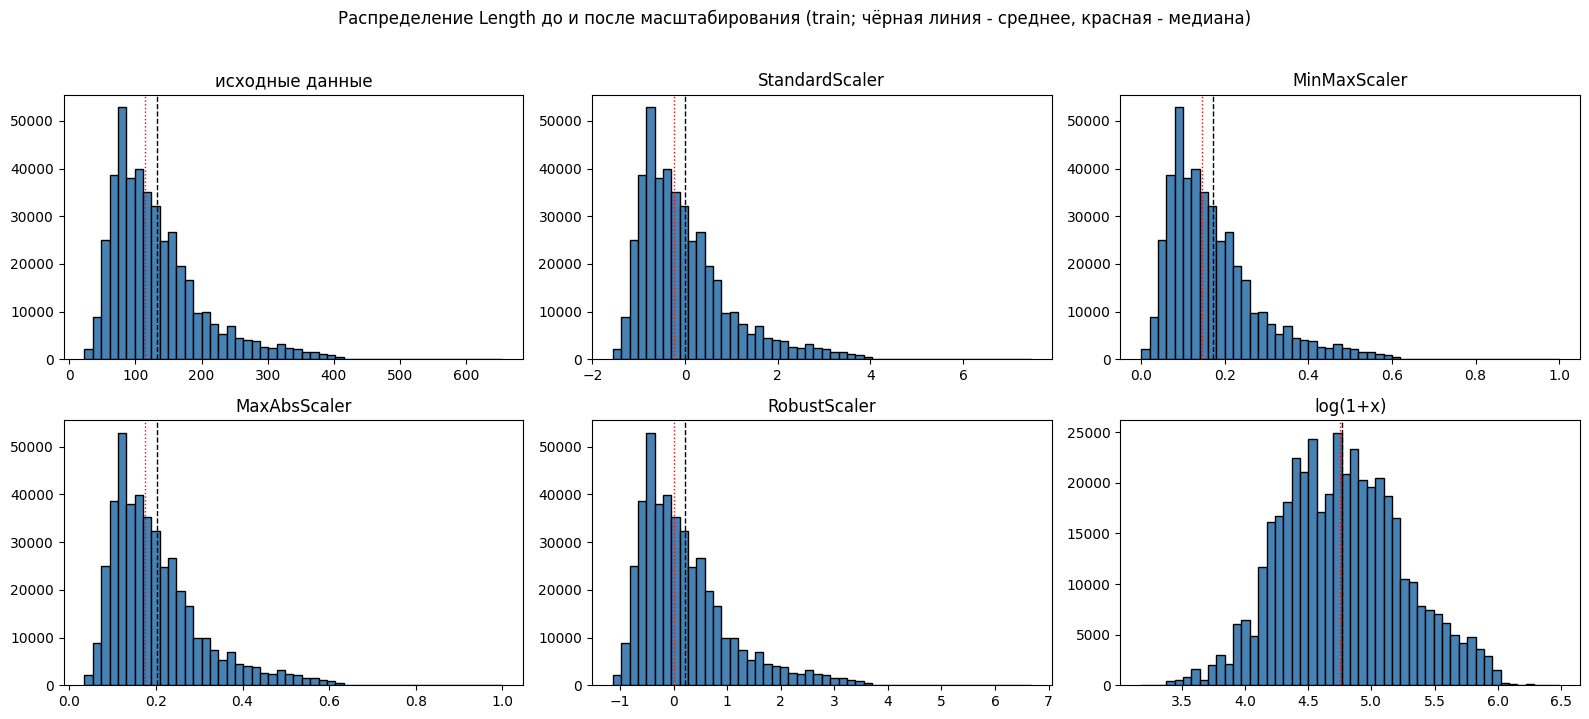

In [65]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, (name, values) in zip(axes.ravel(), scaled.items()):
    ax.hist(values, bins=50, color="steelblue", edgecolor="black")
    ax.axvline(values.mean(), color="black", ls="--", lw=1)
    ax.axvline(values.median(), color="red", ls=":", lw=1)
    ax.set_title(name)
plt.suptitle(f"Распределение {feature} до и после масштабирования (train; чёрная линия - среднее, красная - медиана)", y=1.02)
plt.tight_layout()
plt.show()

In [66]:
# test преобразован скейлерами, обученными на train: среднее и отклонение близки к train, но не равны точно
pd.DataFrame({k: v.describe() for k, v in scaled_test.items()}).T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
исходные данные,132.3,70.33,24,655
StandardScaler,0.002,1.004,-1.544,7.462
MinMaxScaler,0.173,0.111,0.002,1
MaxAbsScaler,0.202,0.107,0.037,1
RobustScaler,0.214,0.868,-1.123,6.667
log(1+x),4.772,0.487,3.219,6.486


Что получилось:
- **StandardScaler** сделал среднее 0 и стандартное отклонение 1. Форма та же, хвост справа уходит за 5.
- **MinMaxScaler** сжал значения в отрезок от 0 до 1. Форма не изменилась, и из-за длинного хвоста почти все рейсы оказались ближе к 0-0,3.
- **MaxAbsScaler** делит на максимум по модулю. Так как длительность всегда положительная, результат почти такой же, как у MinMaxScaler (от 0 до 1). Этот метод полезен для разреженных данных и данных со знаком, нам он ничего не даёт.
- **RobustScaler** использует медиану и IQR, поэтому выбросы на него влияют меньше. Медиана стала ровно 0, основная масса лежит примерно от -1 до 1.
- **log(1+x)** единственный изменил форму: хвост сжался, распределение стало ближе к симметричному.

На test средние и отклонения после StandardScaler не ровно 0 и 1, а чуть другие. Так и должно быть: скейлер обучен на train, и test его не «видел».

Вывод: первые четыре способа только меняют шкалу, а логарифм меняет распределение. Для деревьев масштаб не важен, а для логистической регрессии и kNN я бы взял логарифм и потом StandardScaler (или сразу RobustScaler, если логарифм не нужен).

## 5 Итог
- Данные очищены: нули в длительности заменены медианой маршрута, подозрительные строки помечены флагом, типы исправлены, ничего не удалено.
- Сформулированы и проверены на отложенных 70% три гипотезы, все три подтвердились (третья со слабым эффектом).
- Скейлеры обучены только на train, test преобразован обученными скейлерами (без утечки данных).
- Выбросы в `Length` по правилу IQR - это реальные дальние рейсы, их не удаляю.
- Для `Length` лучший вариант - логарифм, он убирает скошенность. Из обычных скейлеров устойчивее всех к выбросам RobustScaler.